# Bước 2: Phân tích thống kê tài chính
Notebook đọc **dữ liệu sạch**, phục vụ lựa chọn 8 đặc trưng trong `pipeline.md`, chưa chấm điểm hay chọn trọng số. Mỗi bảng ghi rõ đơn vị là hồ sơ hay khách hàng. Chỉ đưa bảng tổng hợp và dữ liệu cấp khách cần thiết sang pandas; xử lý dữ liệu lớn bằng DuckDB. Không sửa CSV hoặc database của EDA.

Ngày chốt: hết **04/06/2025**. Các tỷ lệ quá hạn/xóa sổ là dấu hiệu **đã quan sát**, không phải xác suất vỡ nợ tương lai. Quan hệ đồng thời không chứng minh nhân quả. Không dùng CALL vì thời gian không đồng bộ và không cần cho 8 đặc trưng này.

Chạy từ đầu đến cuối bằng Python có `duckdb`, `pandas`, `numpy`, `matplotlib`, `ipykernel`. Có thể mở notebook từ thư mục dự án hoặc thư mục dataset.

In [1]:
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path('clean_data')
if not DATA_DIR.is_dir():
    DATA_DIR = Path('BI10_ROUND02_DATASET/clean_data')
assert DATA_DIR.is_dir(), 'Mở notebook từ thư mục dự án hoặc dataset.'
SNAPSHOT = pd.Timestamp('2025-06-04')
END = '2025-06-05'  # cận trên loại trừ, bao gồm trọn ngày chốt
con = duckdb.connect(':memory:')
con.execute("SET memory_limit='2GB'")
con.execute('SET threads=4')
con.execute('SET preserve_insertion_order=false')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 180)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})

def q(sql):
    return con.sql(sql).df()

for table, file in [('customer', 'CUSTOMER_clean.csv'), ('contract_raw', 'CONTRACT_clean.csv'), ('behavior', 'PAST_BEHAVIOR_clean.csv')]:
    path = (DATA_DIR / file).resolve().as_posix().replace("'", "''")
    con.execute(f"CREATE VIEW {table} AS SELECT * FROM read_csv_auto('{path}', sample_size=-1)")
print('Nguồn:', DATA_DIR.resolve(), '| Ngày chốt:', SNAPSHOT.date())

Nguồn: C:\Users\nguyen\Desktop\BI_r2\BI10_ROUND02_DATASET\clean_data | Ngày chốt: 2025-06-04


## 1. Phạm vi và định nghĩa 8 đặc trưng
- **DTI:** tổng ANNUITY của hợp đồng Active / thu nhập chính ở hồ sơ gần nhất. Thu nhập nằm trong CONTRACT, không phải CUSTOMER. Không tìm ngược để tự thay thu nhập 0 bằng một thu nhập cũ.
- **Income_Stability:** khảo sát NAME_INCOME_TYPE ở hồ sơ gần nhất; không có lịch sử lương hay NAME_SALARY_FREQUENCY trong clean nên chưa đo được độ ổn định thực. Không tự xếp hạng nghề nghiệp.
- **Early_Delinquency_Index:** số cờ trễ, tỷ lệ hồ sơ có cờ trễ và mẫu hình 4 kỳ; cờ nhị phân không cho biết số ngày hay số tiền trễ.
- **Contract_Completion_Ratio:** Finished / hồ sơ đã ký; trình bày riêng phương án cộng Paid off, tỷ lệ Written off / đã ký và Rejected / toàn bộ hồ sơ.
- **Down_Payment_Ratio:** INIT_PAY / (INIT_PAY + AMT_CREDIT), chỉ CD/TW có số tiền hợp lệ.
- **Buffer_And_Protection:** chỉ còn FLAG_INS, không có FLAG_CAR_OWNER; bảo hiểm không chứng minh có tài sản hay chủ động mua.
- **Credit_Hunger_Velocity:** số sự kiện và hồ sơ trong 30/60/90 ngày, số ngày hoạt động, khoảng cách nộp hồ sơ. Tần suất chưa tự nó chứng minh căng thẳng tài chính.
- **Digital_Engagement:** AVG_SESSION_PER_WEEK_2025. Chưa biết khoảng thời gian dùng để tính trung bình nên chỉ phân tích mô tả, không dùng kiểm chứng theo thời gian.

Hợp đồng ký >=120 ngày trước ngày chốt được dùng như **nhóm đủ tuổi quan sát theo giả định**, không phải xác nhận đã đến đủ 4 kỳ. Thiếu lịch trả nợ thực tế; phân tích độ nhạy 90/120/180 ngày ở dưới. Không thay ngày ký thiếu bằng ngày nộp để khẳng định đủ tuổi.

In [2]:
con.execute(f"""
CREATE TABLE c AS
SELECT SKP_CLIENT, SKP_CREDIT_CASE, PRODUCT, NAME_CREDIT_STATUS, IS_SIGNED,
       APPLY_CONTRACT_TIME, SIGN_CONTRACT_TIME, AMT_INCOME_MAIN, NAME_INCOME_TYPE,
       ANNUITY, AMT_CREDIT, INIT_PAY, FLAG_INS,
       FIRST_DUE, SECOND_DUE, THIRD_DUE, FOURTH_DUE,
       CASE WHEN FIRST_DUE IN (0,1) AND SECOND_DUE IN (0,1)
                  AND THIRD_DUE IN (0,1) AND FOURTH_DUE IN (0,1)
            THEN greatest(FIRST_DUE, SECOND_DUE, THIRD_DUE, FOURTH_DUE) END AS any_due,
       CASE WHEN FIRST_DUE IN (0,1) AND SECOND_DUE IN (0,1)
                  AND THIRD_DUE IN (0,1) AND FOURTH_DUE IN (0,1)
            THEN FIRST_DUE + SECOND_DUE + THIRD_DUE + FOURTH_DUE END AS due_count,
       date_diff('day', SIGN_CONTRACT_TIME::date, DATE '{SNAPSHOT.date()}') AS signed_age,
       CASE WHEN PRODUCT IN ('CD','TW') AND INIT_PAY >= 0 AND AMT_CREDIT > 0
            THEN INIT_PAY / (INIT_PAY + AMT_CREDIT) END AS down_payment
FROM contract_raw WHERE APPLY_CONTRACT_TIME < TIMESTAMP '{END}'
""")
display(q("""SELECT count(*) n_cases, count(DISTINCT SKP_CREDIT_CASE) unique_cases,
 count(DISTINCT SKP_CLIENT) n_clients, sum(IS_SIGNED) signed_cases,
 count(*) FILTER (WHERE IS_SIGNED=1 AND any_due IS NULL) unknown_due,
 count(*) FILTER (WHERE IS_SIGNED=1 AND SIGN_CONTRACT_TIME IS NULL) missing_sign_date,
 count(*) FILTER (WHERE SIGN_CONTRACT_TIME >= TIMESTAMP '2025-06-05') future_sign_date
 FROM c"""))
assert q('SELECT count(*) = count(DISTINCT SKP_CREDIT_CASE) ok FROM c').iloc[0,0]
display(q("""SELECT PRODUCT, count(*) n_cases, sum(IS_SIGNED) n_signed,
 count(*) FILTER (WHERE NAME_CREDIT_STATUS='Active') n_active,
 count(*) FILTER (WHERE NAME_CREDIT_STATUS='Active' AND (ANNUITY IS NULL OR ANNUITY<=0)) active_annuity_unusable,
 count(*) FILTER (WHERE AMT_INCOME_MAIN IS NULL OR AMT_INCOME_MAIN<=0) income_unusable,
 count(*) FILTER (WHERE IS_SIGNED=1 AND signed_age>=120) signed_age_120
 FROM c GROUP BY 1 ORDER BY n_cases DESC"""))

,n_cases,unique_cases,n_clients,signed_cases,unknown_due,missing_sign_date,future_sign_date
0,4280377,4280377,1000528,2887190.0,0,218712,0


,PRODUCT,n_cases,n_signed,n_active,active_annuity_unusable,income_unusable,signed_age_120
0,CD,3095684,2109898.0,414505,303,3951,1858450
1,CL,565521,377312.0,160171,804,2600,328383
2,BNPL,211481,178192.0,172234,172234,3,163031
3,CC,135823,98597.0,57467,57467,16,90676
4,TW,133928,100793.0,38447,0,61,80373
5,CW,109591,22397.0,4691,0,648,21600
6,NaN,28348,0.0,0,0,3822,0
7,IN,1,1.0,0,0,0,1


## 2. Tạo bảng một dòng mỗi khách
Giữ tất cả khách của CUSTOMER. Thu nhập/loại thu nhập lấy **cùng hồ sơ gần nhất**, phá hòa bằng SKP_CREDIT_CASE; báo tuổi thông tin và số giá trị thu nhập khác nhau trong 365 ngày, không gọi mọi thay đổi theo thời gian là lỗi.

DTI chỉ có khi có Active, thu nhập dương và **mọi Active có ANNUITY dương**. `dti_observed` giữ riêng tổng phần quan sát được để thấy độ thiếu phủ; không coi nó là DTI đầy đủ. Không Active là một nhóm riêng, không gán điểm tốt vì DTI=0. Ngay DTI đầy đủ trong bộ dữ liệu cũng không bao gồm nợ tại tổ chức khác hay chi phí sinh hoạt.

Tỷ lệ thanh toán dùng hồ sơ đã ký. Khách chưa từng ký có tỷ lệ thanh toán trống, không phải 0% rủi ro.

In [3]:
con.execute(f"""
CREATE TABLE client AS
WITH latest AS (
 SELECT SKP_CLIENT, AMT_INCOME_MAIN income, NAME_INCOME_TYPE income_type,
        date_diff('day', APPLY_CONTRACT_TIME::date, DATE '{SNAPSHOT.date()}') income_age
 FROM c QUALIFY row_number() OVER (PARTITION BY SKP_CLIENT
 ORDER BY APPLY_CONTRACT_TIME DESC, SKP_CREDIT_CASE DESC)=1
), agg AS (
 SELECT SKP_CLIENT, count(*) n_cases, sum(IS_SIGNED) n_signed,
 count(*) FILTER (WHERE NAME_CREDIT_STATUS='Active') n_active,
 count(*) FILTER (WHERE NAME_CREDIT_STATUS='Active' AND ANNUITY>0) n_active_known,
 sum(ANNUITY) FILTER (WHERE NAME_CREDIT_STATUS='Active' AND ANNUITY>0) observed_annuity,
 count(DISTINCT AMT_INCOME_MAIN) FILTER (WHERE AMT_INCOME_MAIN>0
   AND APPLY_CONTRACT_TIME >= TIMESTAMP '{END}' - INTERVAL 365 DAY) income_values_365,
 count(any_due) FILTER (WHERE IS_SIGNED=1) n_due_known,
 avg(any_due) FILTER (WHERE IS_SIGNED=1) due_rate,
 max(any_due) FILTER (WHERE IS_SIGNED=1) ever_due,
 avg(due_count/4.0) FILTER (WHERE IS_SIGNED=1) early_index,
 avg(any_due) FILTER (WHERE IS_SIGNED=1 AND signed_age>=120) mature_due_rate,
 count(any_due) FILTER (WHERE IS_SIGNED=1 AND signed_age>=120) n_mature,
 avg((NAME_CREDIT_STATUS='Finished')::int) FILTER (WHERE IS_SIGNED=1) completion_ratio,
 avg((NAME_CREDIT_STATUS IN ('Finished','Paid off'))::int) FILTER (WHERE IS_SIGNED=1) completion_with_paid,
 avg((NAME_CREDIT_STATUS='Written off')::int) FILTER (WHERE IS_SIGNED=1) writeoff_ratio,
 max((NAME_CREDIT_STATUS='Written off')::int) FILTER (WHERE IS_SIGNED=1) ever_writeoff,
 avg((NAME_CREDIT_STATUS='Rejected')::int) rejection_ratio,
 avg(down_payment) FILTER (WHERE IS_SIGNED=1) down_payment_ratio,
 avg(CASE WHEN FLAG_INS IN (0,1) THEN FLAG_INS END) FILTER (WHERE IS_SIGNED=1) insurance_ratio
 FROM c GROUP BY 1
)
SELECT u.SKP_CLIENT, u.AVG_SESSION_PER_WEEK_2025 app_sessions, a.* EXCLUDE(SKP_CLIENT), l.* EXCLUDE(SKP_CLIENT),
 CASE WHEN n_active>0 AND income>0 THEN observed_annuity/income END dti_observed,
 CASE WHEN n_active>0 AND n_active_known=n_active AND income>0
      THEN observed_annuity/income END dti,
 CASE WHEN n_active=0 THEN '1. No active'
      WHEN income IS NULL OR income<=0 THEN '2. Income unavailable'
      WHEN n_active_known<n_active THEN '3. Partial obligation'
      ELSE '4. Complete observed DTI' END dti_coverage
FROM customer u LEFT JOIN agg a USING(SKP_CLIENT) LEFT JOIN latest l USING(SKP_CLIENT)
""")
display(q("""SELECT count(*) n_clients, count(DISTINCT SKP_CLIENT) unique_clients,
 count(*) FILTER (WHERE n_signed=0) no_signed_history,
 count(*) FILTER (WHERE income_values_365>1) multiple_incomes_365,
 quantile_cont(income_age, [0.5,0.9,0.99]) income_age_days,
 count(*) FILTER (WHERE income_age>180) income_older_180d
 FROM client"""))
display(q('SELECT dti_coverage, count(*) n_clients FROM client GROUP BY 1 ORDER BY 1'))
assert q('SELECT count(*)=count(DISTINCT SKP_CLIENT) ok FROM client').iloc[0,0]
assert q('SELECT count(*) FROM client').iloc[0,0] == q('SELECT count(*) FROM customer').iloc[0,0]

,n_clients,unique_clients,no_signed_history,multiple_incomes_365,income_age_days,income_older_180d
0,1000528,1000528,182505,252357,"[145.0, 177.0, 185.0]",53191


,dti_coverage,n_clients
0,1. No active,395942
1,2. Income unavailable,129
2,3. Partial obligation,227180
3,4. Complete observed DTI,377277


## 3. Trụ cột 1: DTI và loại thu nhập
### 3.1. Phân phối, đuôi ngoại lai và độ phủ DTI
Không xóa hoặc winsorize dữ liệu gốc. Histogram giới hạn ở P99 **chỉ để hiển thị**, số điểm ngoài hình được in riêng. Bảng phân vị giữ cả cực trị. Các khoảng DTI dưới đây là khoảng mô tả, chưa phải ngưỡng an toàn hay ngưỡng chấm điểm.

,n_income,nonpositive,income_quantiles,max_income,n_dti,dti_quantiles,max_dti,dti_above_1
0,1000528,172,"[5000000.0, 10000000.0, 12000000.0, 15000000.0...",900000000.0,377277,"[0.0317, 0.08566666666666667, 0.129, 0.201, 0....",3586000.0,315


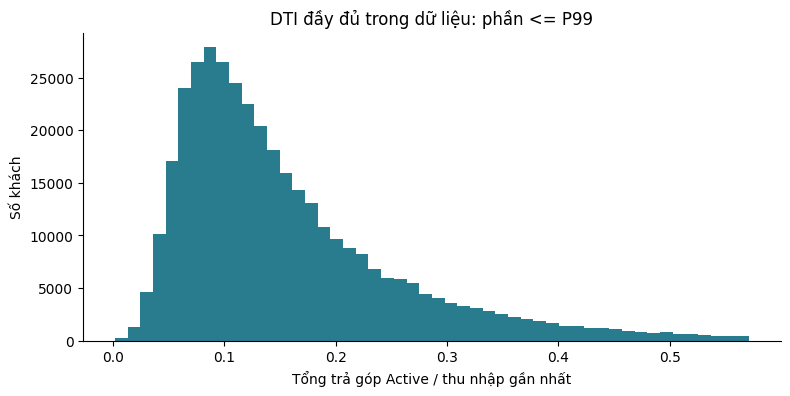

Khách nằm ngoài hình: 3772 | P99: 0.5709


,coverage,n_clients,n_observed,observed_ratio
0,No active,395942,0,<NA>
1,Partial obligations,227234,137801,"[0.1409, 0.3182, 0.5380833333333334]"
2,Complete obligations,377352,377277,"[0.129, 0.3045, 0.5709333333333333]"


,PRODUCT,n_active,n_ratio,case_ratio
0,CD,414505,414197,"[0.101, 0.192, 0.3295]"
1,BNPL,172234,0,<NA>
2,CL,160171,159365,"[0.15195, 0.2822441176470589, 0.43669066666666..."
3,CC,57467,0,<NA>
4,TW,38447,38446,"[0.22264285714285714, 0.3819, 0.5703312500000011]"
5,CW,4691,4691,"[0.1502, 0.2541111111111111, 0.38021568627451]"


case_ratio là tỷ lệ của từng hồ sơ với thu nhập lúc nộp, KHÔNG phải DTI cấp khách.


In [4]:
display(q("""SELECT count(income) n_income, count(*) FILTER (WHERE income<=0) nonpositive,
 quantile_cont(income, [0.01,0.25,0.5,0.75,0.95,0.99]) income_quantiles, max(income) max_income,
 count(dti) n_dti, quantile_cont(dti, [0.01,0.25,0.5,0.75,0.95,0.99]) dti_quantiles, max(dti) max_dti,
 count(*) FILTER (WHERE dti>1) dti_above_1 FROM client"""))
dti_values = q('SELECT dti FROM client WHERE dti IS NOT NULL')['dti']
p99 = dti_values.quantile(.99)
plt.hist(dti_values[dti_values<=p99], bins=50, color='#287c8e')
plt.xlabel('Tổng trả góp Active / thu nhập gần nhất'); plt.ylabel('Số khách')
plt.title('DTI đầy đủ trong dữ liệu: phần <= P99'); plt.show()
print('Khách nằm ngoài hình:', int((dti_values>p99).sum()), '| P99:', round(p99,4))
display(q("""SELECT CASE WHEN n_active=0 THEN 'No active'
 WHEN n_active_known<n_active THEN 'Partial obligations' ELSE 'Complete obligations' END coverage,
 count(*) n_clients, count(dti_observed) n_observed,
 quantile_cont(dti_observed,[0.5,0.9,0.99]) observed_ratio
 FROM client GROUP BY 1"""))
display(q("""SELECT PRODUCT, count(*) n_active,
 count(*) FILTER (WHERE ANNUITY>0 AND AMT_INCOME_MAIN>0) n_ratio,
 quantile_cont(CASE WHEN ANNUITY>0 AND AMT_INCOME_MAIN>0 THEN ANNUITY/AMT_INCOME_MAIN END,
 [0.5,0.9,0.99]) case_ratio FROM c WHERE NAME_CREDIT_STATUS='Active' GROUP BY 1 ORDER BY n_active DESC
"""))
print('case_ratio là tỷ lệ của từng hồ sơ với thu nhập lúc nộp, KHÔNG phải DTI cấp khách.')

### 3.2. DTI và dấu hiệu quá hạn ở cấp khách
Biểu đồ kèm khoảng Wilson 95% cho tỷ lệ khách từng có cờ quá hạn (mỗi khách một quan sát). Đây là tỷ lệ lịch sử, không phải nhãn tương lai; DTI hiện tại có thể được đo sau lần trễ. Nhóm không có lịch sử cờ hợp lệ không vào mẫu số. Không dùng tỷ lệ này để tuyên bố ngưỡng DTI gây ra quá hạn.

Hàm nhỏ dưới đây chỉ dùng chung để vẽ tỷ lệ và hiển thị rõ tử số/mẫu số cho DTI, tần suất và dùng app.

,group_name,n_clients,n_known,n_bad,n_writeoff,pct_bad,low95,high95
0,1. No active,395942,213437,22219.0,13120.0,10.410,10.281,10.540
1,2. Income unavailable,129,129,3.0,0.0,2.326,0.794,6.615
2,3. Partial obligation,227180,227180,11159.0,147.0,4.912,4.824,5.002
3,5. DTI <=20%,282234,282234,13651.0,42.0,4.837,4.758,4.917
4,"6. DTI (20,40]%",78413,78413,3273.0,7.0,4.174,4.036,4.316
5,"7. DTI (40,60]%",13808,13808,425.0,2.0,3.078,2.803,3.379
6,"8. DTI (60,100]%",2507,2507,79.0,1.0,3.151,2.536,3.910
7,9. DTI >100%,315,315,7.0,0.0,2.222,1.081,4.515


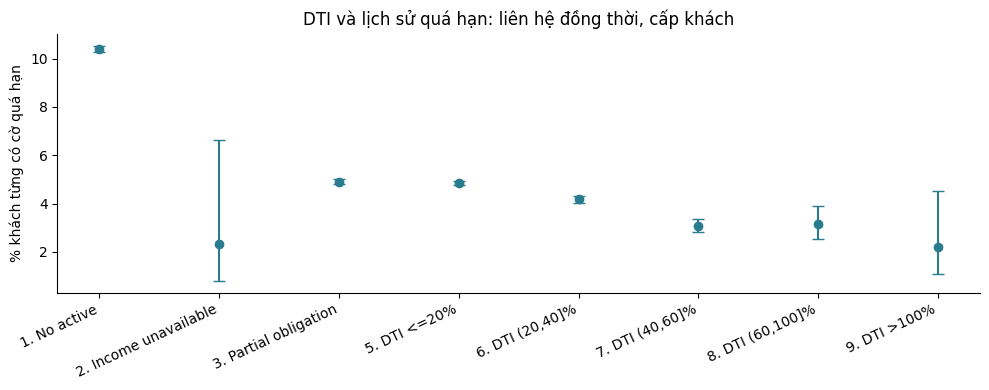

,income_recency,n_dti,median_dti,income_above_100m,median_without_above_100m
0,Older than 180d,12501,0.138143,28,0.138200
1,Within 180d,364776,0.128660,475,0.128714


100 triệu chỉ là ngưỡng kiểm tra độ nhạy, không là quy tắc loại thu nhập.


In [5]:
def rate_plot(table, title):
    t = table.copy()
    n = t['n_known'].astype(float)
    p = t['n_bad'].astype(float) / n.replace(0, np.nan)
    z = 1.96
    center = (p + z*z/(2*n)) / (1+z*z/n)
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1+z*z/n)
    t['pct_bad'] = 100*p
    t['low95'] = 100*(center-half)
    t['high95'] = 100*(center+half)
    display(t.round(3))
    valid = n>0
    plt.figure(figsize=(10,4))
    plt.errorbar(np.arange(valid.sum()), 100*p[valid],
                 yerr=[100*(p-center+half)[valid],100*(center+half-p)[valid]],
                 fmt='o', capsize=4, color='#287c8e')
    plt.xticks(np.arange(valid.sum()), t.loc[valid,'group_name'], rotation=25, ha='right')
    plt.ylabel('% khách từng có cờ quá hạn'); plt.title(title)
    plt.tight_layout(); plt.show()
    return t

dti_groups = q("""WITH x AS (SELECT *, CASE
 WHEN dti IS NULL THEN dti_coverage
 WHEN dti<=.2 THEN '5. DTI <=20%' WHEN dti<=.4 THEN '6. DTI (20,40]%'
 WHEN dti<=.6 THEN '7. DTI (40,60]%' WHEN dti<=1 THEN '8. DTI (60,100]%'
 ELSE '9. DTI >100%' END group_name FROM client)
 SELECT group_name, count(*) n_clients, count(ever_due) n_known, sum(ever_due) n_bad,
 sum(ever_writeoff) n_writeoff FROM x GROUP BY 1 ORDER BY 1""")
dti_evidence = rate_plot(dti_groups, 'DTI và lịch sử quá hạn: liên hệ đồng thời, cấp khách')
display(q("""SELECT CASE WHEN income_age>180 THEN 'Older than 180d' ELSE 'Within 180d' END income_recency,
 count(dti) n_dti, median(dti) median_dti,
 count(*) FILTER (WHERE income>100000000) income_above_100m,
 median(dti) FILTER (WHERE income<=100000000) median_without_above_100m
 FROM client GROUP BY 1"""))
print('100 triệu chỉ là ngưỡng kiểm tra độ nhạy, không là quy tắc loại thu nhập.')

### 3.3. Income_Stability: kiểm tra proxy loại thu nhập
Bảng khách dùng loại thu nhập gần nhất; bảng hồ sơ bên dưới dùng loại thu nhập tại hồ sơ và tách sản phẩm trong nhóm ký >=120 ngày. XNA là thiếu thông tin, không phải một nghề rủi ro. So sánh chưa kiểm soát mọi yếu tố, không tự áp dụng thứ bậc Employed > Self-employed.

,group_name,n_clients,n_known,n_bad,n_dti,median_dti,pct_bad,low95,high95
0,Employed person,414994,402346,18595.0,225863,0.133,4.622,4.557,4.687
1,Self-employed person / business owner,294715,283620,13820.0,125452,0.121,4.873,4.794,4.953
2,XNA,279058,122487,18039.0,20898,0.129,14.727,14.530,14.927
3,Student,6420,5593,212.0,3172,0.175,3.790,3.321,4.323
4,Person in household,3403,2361,88.0,1010,0.216,3.727,3.035,4.570
5,Retired person,1247,1182,48.0,686,0.121,4.061,3.076,5.343
6,Unemployed,691,434,14.0,196,0.223,3.226,1.931,5.341


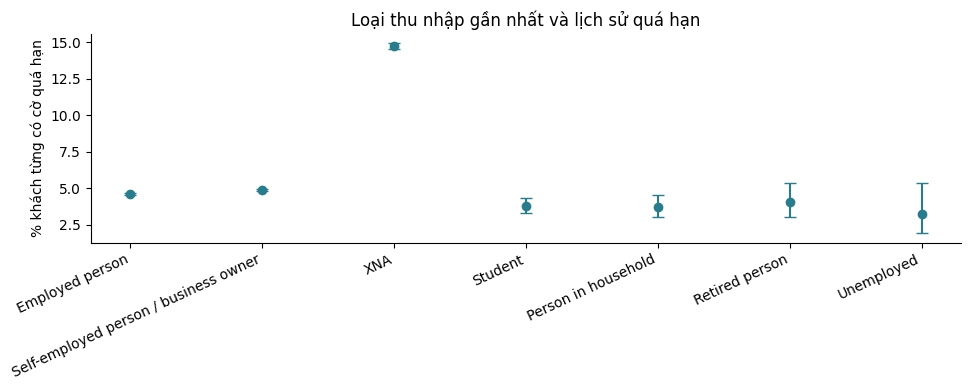

,PRODUCT,income_type,n_cases,n_known,n_bad,pct_due
0,BNPL,Self-employed person / business owner,108783,108783,2412.0,2.217258
1,BNPL,Employed person,52421,52421,1136.0,2.167070
2,BNPL,Student,1678,1678,48.0,2.860548
3,BNPL,Retired person,135,135,2.0,1.481481
4,BNPL,Person in household,14,14,0.0,0.000000
5,CC,Employed person,63701,63701,1315.0,2.064332
6,CC,Self-employed person / business owner,26384,26384,714.0,2.706186
7,CC,Student,320,320,7.0,2.187500
8,CC,Person in household,197,197,12.0,6.091371
9,CC,Retired person,38,38,4.0,10.526316


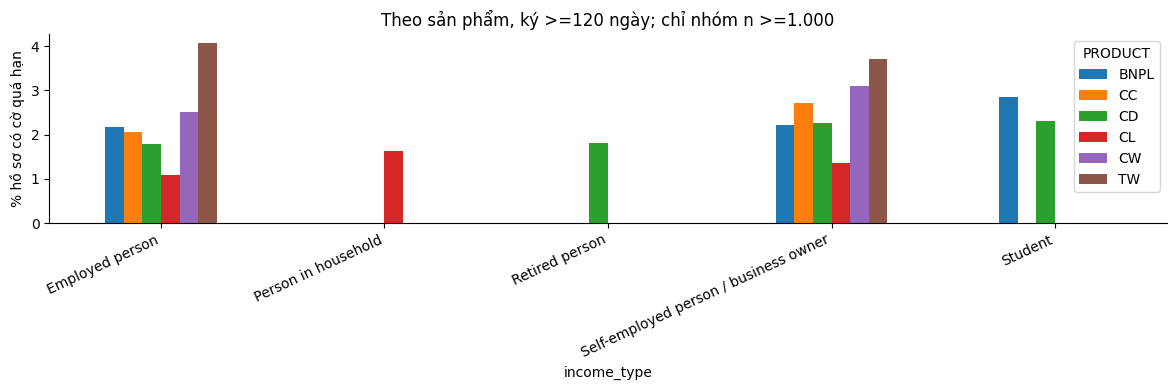

Các nhóm nhỏ vẫn nằm trong bảng, chỉ ẩn khỏi hình để tránh diễn giải quá mức.


In [6]:
income_groups = q("""SELECT coalesce(income_type,'Missing') group_name, count(*) n_clients,
 count(ever_due) n_known, sum(ever_due) n_bad, count(dti) n_dti, median(dti) median_dti
 FROM client GROUP BY 1 ORDER BY n_clients DESC""")
income_evidence = rate_plot(income_groups, 'Loại thu nhập gần nhất và lịch sử quá hạn')
income_product = q("""SELECT PRODUCT, coalesce(NAME_INCOME_TYPE,'Missing') income_type,
 count(*) n_cases, count(any_due) n_known, sum(any_due) n_bad, 100*avg(any_due) pct_due
 FROM c WHERE IS_SIGNED=1 AND signed_age>=120 GROUP BY 1,2 ORDER BY 1,n_cases DESC""")
display(income_product)
p = income_product[income_product.n_known>=1000].pivot(index='income_type', columns='PRODUCT', values='pct_due')
if not p.empty:
    p.plot.bar(figsize=(12,4)); plt.ylabel('% hồ sơ có cờ quá hạn');
    plt.title('Theo sản phẩm, ký >=120 ngày; chỉ nhóm n >=1.000'); plt.xticks(rotation=25, ha='right'); plt.tight_layout(); plt.show()
print('Các nhóm nhỏ vẫn nằm trong bảng, chỉ ẩn khỏi hình để tránh diễn giải quá mức.')

## 4. Trụ cột 2: Cờ quá hạn và trạng thái hợp đồng
### 4.1. Phân phối 4 kỳ và độ nhạy tuổi hợp đồng
So sánh toàn bộ với nhóm ký >=90/120/180 ngày. Các nhóm này lồng nhau, không độc lập. Tuổi hợp đồng không thay thế lịch đến hạn. Khác biệt theo cohort/sản phẩm cần được xem trước khi gộp thành một chỉ số.

,age_cut,n_signed,n_known,p1,p2,p3,p4,any_pct
0,0,2887190,2887190,0.487983,0.750072,1.012161,1.228253,1.965094
1,90,2565641,2565641,0.483388,0.740945,1.007273,1.204572,1.943413
2,120,2542514,2542514,0.477716,0.731913,1.003298,1.215411,1.937885
3,180,1846489,1846489,0.310752,0.561715,0.785328,1.019177,1.653246


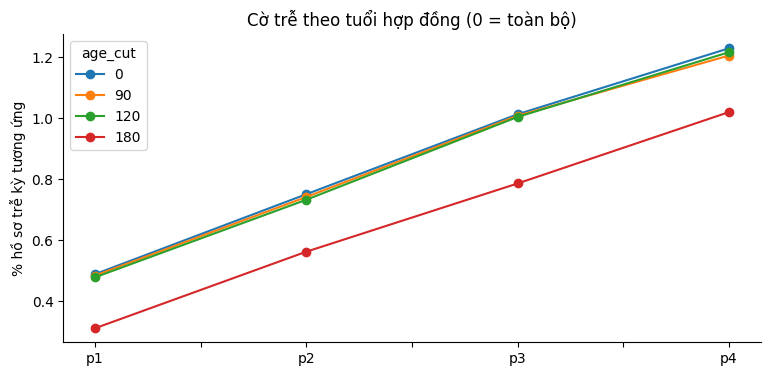

,PRODUCT,n_signed,n_known,n_bad,pct_due,pct_writeoff
0,CD,1858450,1858450,36014.0,1.937851,0.250747
1,CL,328383,328383,3850.0,1.172411,0.724459
2,BNPL,163031,163031,3598.0,2.206942,0.090167
3,CC,90676,90676,2053.0,2.264105,0.373859
4,TW,80373,80373,3174.0,3.949087,1.190698
5,CW,21600,21600,582.0,2.694444,2.898148
6,IN,1,1,0.0,0.000000,0.000000


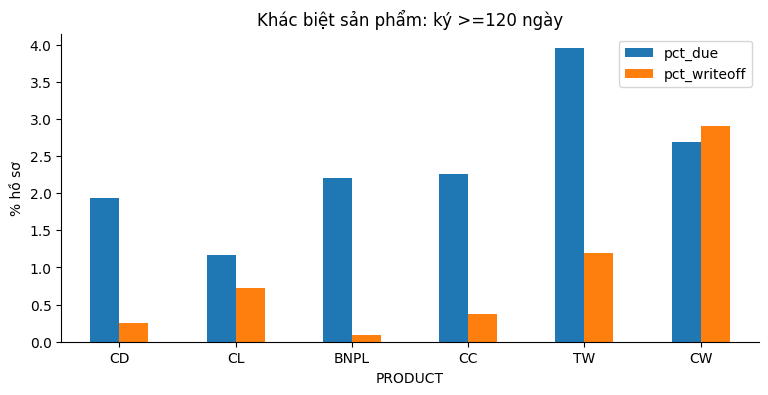

,cohort,PRODUCT,n_known,pct_due
0,2017,CC,31,0.000000
1,2017,CD,86808,1.704912
2,2017,CL,7565,1.440846
3,2017,CW,1189,4.625736
4,2017,TW,3502,2.312964
5,2018,CC,771,1.686122
6,2018,CD,129852,1.759696
7,2018,CL,13124,0.883877
8,2018,CW,551,4.718693
9,2018,TW,5350,2.317757


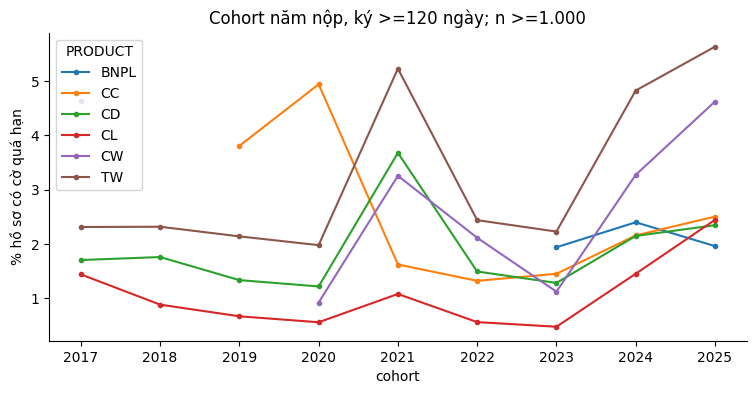

In [7]:
maturity = q("""SELECT age_cut, count(*) n_signed, count(any_due) n_known,
 100*avg(FIRST_DUE) p1, 100*avg(SECOND_DUE) p2, 100*avg(THIRD_DUE) p3,
 100*avg(FOURTH_DUE) p4, 100*avg(any_due) any_pct
 FROM c CROSS JOIN (VALUES (0),(90),(120),(180)) cuts(age_cut)
 WHERE IS_SIGNED=1 AND (age_cut=0 OR signed_age>=age_cut)
 GROUP BY 1 ORDER BY 1""")
display(maturity)
maturity.set_index('age_cut')[['p1','p2','p3','p4']].T.plot(marker='o')
plt.ylabel('% hồ sơ trễ kỳ tương ứng'); plt.title('Cờ trễ theo tuổi hợp đồng (0 = toàn bộ)'); plt.show()
product_due = q("""SELECT PRODUCT, count(*) n_signed, count(any_due) n_known,
 sum(any_due) n_bad, 100*avg(any_due) pct_due,
 100*avg((NAME_CREDIT_STATUS='Written off')::int) pct_writeoff
 FROM c WHERE IS_SIGNED=1 AND signed_age>=120 GROUP BY 1 ORDER BY n_signed DESC""")
display(product_due)
product_due[product_due.n_known>=1000].set_index('PRODUCT')[['pct_due','pct_writeoff']].plot.bar()
plt.ylabel('% hồ sơ'); plt.title('Khác biệt sản phẩm: ký >=120 ngày'); plt.xticks(rotation=0); plt.show()
cohorts = q("""SELECT year(APPLY_CONTRACT_TIME) cohort, PRODUCT, count(any_due) n_known,
 100*avg(any_due) pct_due FROM c WHERE IS_SIGNED=1 AND signed_age>=120
 GROUP BY 1,2 ORDER BY 1,2""")
display(cohorts)
cohorts[cohorts.n_known>=1000].pivot(index='cohort',columns='PRODUCT',values='pct_due').plot(marker='.')
plt.ylabel('% hồ sơ có cờ quá hạn'); plt.title('Cohort năm nộp, ký >=120 ngày; n >=1.000'); plt.show()

,pattern,due_count,n_cases,n_writeoff,pct_writeoff
0,0000,0,2493243,3829,0.153575
1,0001,1,13006,1003,7.711825
2,0010,1,6282,125,1.989812
3,0011,2,6051,931,15.385887
4,0100,1,4342,66,1.520037
5,0101,2,951,81,8.517350
6,0110,2,1569,60,3.824092
7,0111,3,4924,1121,22.766044
8,1000,1,4152,67,1.613680
9,1001,2,347,24,6.916427


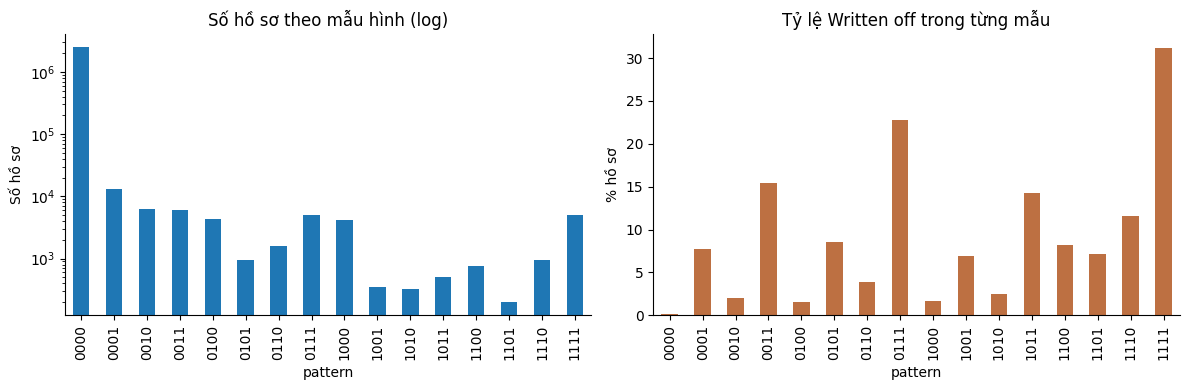

,endpoints,n_cases,mean_flag_count,pct_writeoff
0,0 -> 0,2505436,0.005493,0.162846
1,0 -> 1,24932,1.675838,12.578213
2,1 -> 0,6176,1.479437,3.983161
3,1 -> 1,5970,3.766332,27.571189


0 -> 1 chỉ là khác biệt cờ kỳ 1/4; không chứng minh số ngày trễ tăng hay kỳ 1 quên trả.


In [8]:
patterns = q("""SELECT concat(FIRST_DUE,SECOND_DUE,THIRD_DUE,FOURTH_DUE) pattern,
 due_count, count(*) n_cases,
 count(*) FILTER (WHERE NAME_CREDIT_STATUS='Written off') n_writeoff,
 100*avg((NAME_CREDIT_STATUS='Written off')::int) pct_writeoff
 FROM c WHERE IS_SIGNED=1 AND signed_age>=120 AND any_due IS NOT NULL
 GROUP BY 1,2 ORDER BY 1""")
display(patterns)
fig, axes = plt.subplots(1,2,figsize=(12,4))
patterns.plot.bar(x='pattern', y='n_cases', ax=axes[0], legend=False, logy=True)
patterns.plot.bar(x='pattern', y='pct_writeoff', ax=axes[1], legend=False, color='#bd7042')
axes[0].set_title('Số hồ sơ theo mẫu hình (log)'); axes[0].set_ylabel('Số hồ sơ')
axes[1].set_title('Tỷ lệ Written off trong từng mẫu'); axes[1].set_ylabel('% hồ sơ')
plt.tight_layout(); plt.show()
display(q("""SELECT CASE WHEN FIRST_DUE=0 AND FOURTH_DUE=1 THEN '0 -> 1'
 WHEN FIRST_DUE=1 AND FOURTH_DUE=0 THEN '1 -> 0'
 WHEN FIRST_DUE=1 AND FOURTH_DUE=1 THEN '1 -> 1' ELSE '0 -> 0' END endpoints,
 count(*) n_cases, avg(due_count) mean_flag_count,
 100*avg((NAME_CREDIT_STATUS='Written off')::int) pct_writeoff
 FROM c WHERE IS_SIGNED=1 AND signed_age>=120 AND any_due IS NOT NULL
 GROUP BY 1 ORDER BY 1"""))
print('0 -> 1 chỉ là khác biệt cờ kỳ 1/4; không chứng minh số ngày trễ tăng hay kỳ 1 quên trả.')

### 4.2. Contract_Completion_Ratio
Không gộp Paid off với Finished trước khi xem bằng chứng. Rejected là quyết định hồ sơ, không là mất khả năng thanh toán. Tỷ lệ hoàn tất còn phụ thuộc tuổi danh mục: khách mới có nhiều Active không đồng nghĩa kém kỷ luật. Liên hệ Written off với cờ quá hạn là mô tả đồng thời, không là validation độc lập nếu cả hai cùng dùng trong score.

,NAME_CREDIT_STATUS,IS_SIGNED,n_cases,n_flag_known,n_flagged,pct_flagged,n_age120,pct_flagged_age120
0,Finished,1,2017785,2017785,27249.0,1.350441,1804067,1.299675
1,Rejected,0,914467,914467,0.0,0.000000,0,NaN
2,Active,1,847515,847515,17117.0,2.019669,723750,2.204214
3,Cancelled,0,477677,477677,0.0,0.000000,74202,0.000000
4,Written off,1,14520,14520,7769.0,53.505510,9108,57.960035
5,Paid off,1,5598,5598,4601.0,82.190068,5589,82.161388
6,Signed,1,1772,1772,0.0,0.000000,0,NaN
7,Approved,0,483,483,0.0,0.000000,0,NaN
8,Sold,0,387,387,188.0,48.578811,146,59.589041
9,In Preprocess,0,159,159,0.0,0.000000,0,NaN


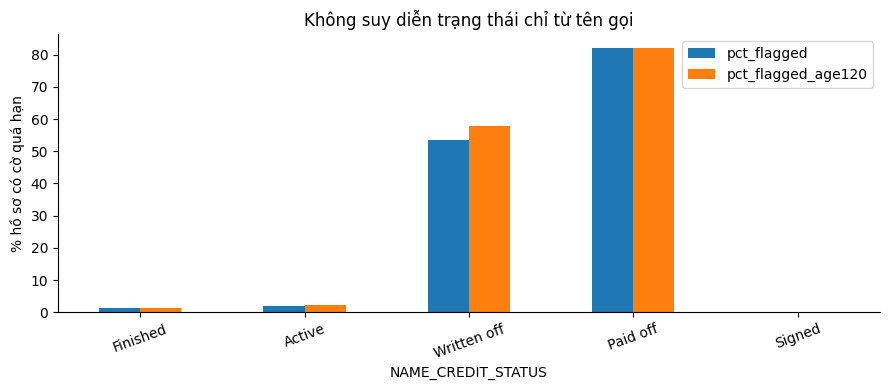

,n_clients,finished_ratio,finished_plus_paid_ratio,affected_by_paid,clients_written_off,median_rejection_ratio
0,818023,"[0.0, 0.3333333333333333, 0.6666666666666666, ...","[0.0, 0.3333333333333333, 0.6666666666666666, ...",5073,13319,0.0


,history,n_clients,mean_finished_ratio,mean_writeoff_ratio,mean_rejection_ratio
0,1 signed,216587,0.350076,0.028224,0.173949
1,2-5 signed,441806,0.622351,0.006647,0.117104
2,6+ signed,159630,0.797591,0.000812,0.092870
3,No signed history,182505,NaN,NaN,0.829270


In [9]:
status = q("""SELECT NAME_CREDIT_STATUS, IS_SIGNED, count(*) n_cases,
 count(any_due) n_flag_known, sum(any_due) n_flagged, 100*avg(any_due) pct_flagged,
 count(*) FILTER (WHERE signed_age>=120) n_age120,
 100*avg(any_due) FILTER (WHERE signed_age>=120) pct_flagged_age120
 FROM c GROUP BY 1,2 ORDER BY n_cases DESC""")
display(status)
status[status.IS_SIGNED==1].plot.bar(x='NAME_CREDIT_STATUS',y=['pct_flagged','pct_flagged_age120'])
plt.ylabel('% hồ sơ có cờ quá hạn'); plt.title('Không suy diễn trạng thái chỉ từ tên gọi'); plt.xticks(rotation=20); plt.tight_layout(); plt.show()
display(q("""SELECT count(*) n_clients,
 quantile_cont(completion_ratio,[0,.25,.5,.75,1]) finished_ratio,
 quantile_cont(completion_with_paid,[0,.25,.5,.75,1]) finished_plus_paid_ratio,
 count(*) FILTER (WHERE completion_with_paid>completion_ratio) affected_by_paid,
 count(*) FILTER (WHERE ever_writeoff=1) clients_written_off,
 median(rejection_ratio) median_rejection_ratio FROM client WHERE n_signed>0"""))
display(q("""SELECT CASE WHEN n_signed=0 THEN 'No signed history'
 WHEN n_signed=1 THEN '1 signed' WHEN n_signed<=5 THEN '2-5 signed' ELSE '6+ signed' END history,
 count(*) n_clients, avg(completion_ratio) mean_finished_ratio,
 avg(writeoff_ratio) mean_writeoff_ratio, avg(rejection_ratio) mean_rejection_ratio
 FROM client GROUP BY 1 ORDER BY 1"""))

## 5. Trụ cột 3: Trả trước và bảo hiểm
### 5.1. Down_Payment_Ratio
Đơn vị: hồ sơ đã ký CD/TW. Bảng đầu giữ mọi tuổi hồ sơ để xem phân phối/độ phủ; bảng liên hệ dùng ký >=120 ngày và tách sản phẩm. Khách có nhiều hồ sơ đóng góp nhiều dòng ở đây. Các khoảng 10% chỉ phục vụ quan sát hình dạng; không là điểm cắt scoring.

,PRODUCT,n_signed,n_usable,n_unusable,quantiles
0,TW,100793,100793,0,"[0.0, 0.24528301886792453, 0.34121621621621623..."
1,CD,2109898,2109594,304,"[0.0, 0.2033898305084746, 0.3, 0.3005008347245..."


,PRODUCT,decile_band,n_cases,n_known,n_bad,pct_due
0,CD,0,60183,60183,826.0,1.372481
1,CD,1,222522,222522,6464.0,2.904881
2,CD,2,277271,277271,6367.0,2.296309
3,CD,3,982356,982356,17814.0,1.813396
4,CD,4,183679,183679,2931.0,1.595719
5,CD,5,111911,111911,1423.0,1.271546
6,CD,6,15288,15288,150.0,0.981162
7,CD,7,4394,4394,32.0,0.728266
8,CD,8,317,317,1.0,0.315457
9,CD,9,225,225,3.0,1.333333


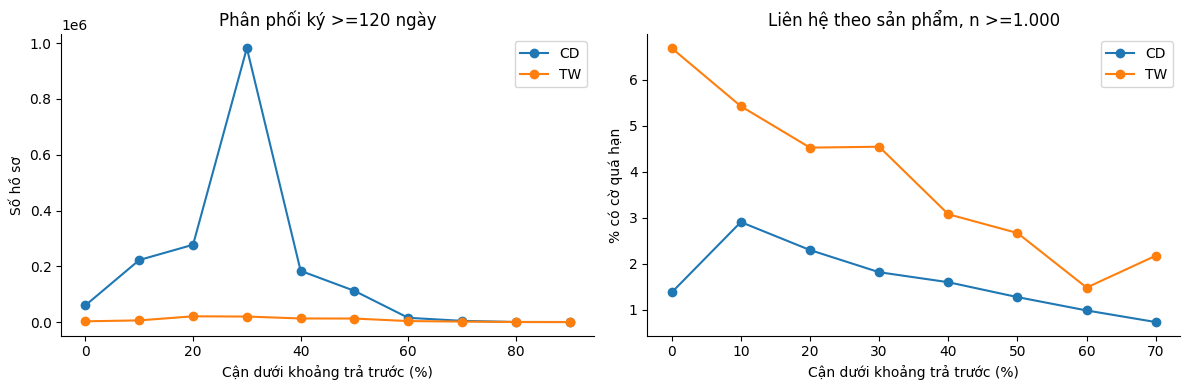

In [10]:
display(q("""SELECT PRODUCT, count(*) n_signed, count(down_payment) n_usable,
 count(*) FILTER (WHERE down_payment IS NULL) n_unusable,
 quantile_cont(down_payment,[0,.25,.5,.75,.95,.99,1]) quantiles
 FROM c WHERE IS_SIGNED=1 AND PRODUCT IN ('CD','TW') GROUP BY 1"""))
down = q("""SELECT PRODUCT, least(floor(down_payment*10)::int,9) decile_band,
 count(*) n_cases, count(any_due) n_known, sum(any_due) n_bad, 100*avg(any_due) pct_due
 FROM c WHERE IS_SIGNED=1 AND signed_age>=120 AND down_payment IS NOT NULL
 GROUP BY 1,2 ORDER BY 1,2""")
display(down)
fig, axes = plt.subplots(1,2,figsize=(12,4))
for product, g in down.groupby('PRODUCT'):
    axes[0].plot(g.decile_band*10, g.n_cases, marker='o', label=product)
    visible = g[g.n_known>=1000]
    axes[1].plot(visible.decile_band*10, visible.pct_due, marker='o', label=product)
for ax in axes:
    ax.set_xlabel('Cận dưới khoảng trả trước (%)'); ax.legend()
axes[0].set_ylabel('Số hồ sơ'); axes[1].set_ylabel('% có cờ quá hạn')
axes[0].set_title('Phân phối ký >=120 ngày'); axes[1].set_title('Liên hệ theo sản phẩm, n >=1.000')
plt.tight_layout(); plt.show()

### 5.2. Buffer_And_Protection: chỉ có proxy bảo hiểm
Không đo được đệm tài sản. Tách FLAG_INS thiếu/ngoài 0–1 khỏi không có bảo hiểm. So sánh theo sản phẩm và cohort để tránh cộng điểm chỉ vì một sản phẩm thường bán kèm bảo hiểm. Không thể kết luận mua bảo hiểm làm giảm quá hạn từ bảng này.

,PRODUCT,insurance,n_cases,n_known,n_bad,pct_due,pct_writeoff
0,BNPL,Not insured,163031,163031,3598.0,2.206942,0.090167
1,CC,Insured,30578,30578,828.0,2.707829,0.533063
2,CC,Not insured,60098,60098,1225.0,2.038337,0.292855
3,CD,Insured,669299,669299,12868.0,1.922609,0.332139
4,CD,Not insured,1189151,1189151,23146.0,1.946431,0.204936
5,CL,Insured,231344,231344,3068.0,1.326164,0.841172
6,CL,Not insured,97039,97039,782.0,0.805862,0.446212
7,CW,Insured,15481,15481,484.0,3.126413,3.507525
8,CW,Not insured,6119,6119,98.0,1.601569,1.356431
9,IN,Insured,1,1,0.0,0.000000,0.000000


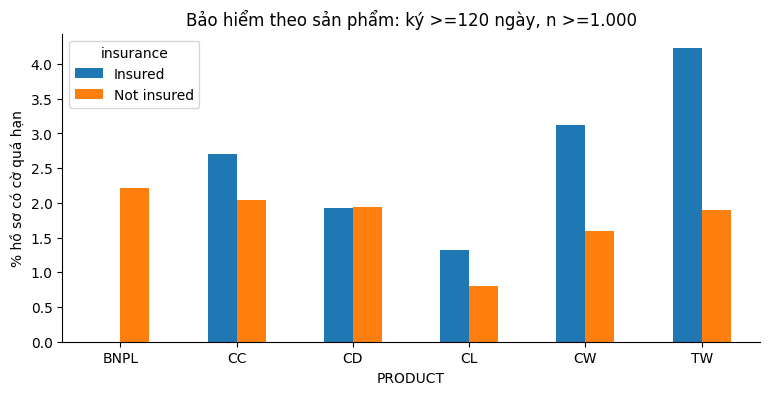

,PRODUCT,cohort,FLAG_INS,n_cases,n_known,n_bad,pct_due
0,BNPL,2022,0,117,117,3.0,2.564103
1,BNPL,2023,0,3196,3196,62.0,1.939925
2,BNPL,2024,0,91209,91209,2189.0,2.399982
3,BNPL,2025,0,68509,68509,1344.0,1.961786
4,CC,2017,0,27,27,0.0,0.000000
...,...,...,...,...,...,...,...
90,TW,2023,1,7864,7864,181.0,2.301628
91,TW,2024,0,1267,1267,14.0,1.104972
92,TW,2024,1,21948,21948,1106.0,5.039184
93,TW,2025,0,634,634,12.0,1.892744


FLAG_INS               0         1  insured_minus_uninsured_pp
PRODUCT cohort                                                
CC      2020    4.289335  5.646014                    1.356679
        2021    1.649802  1.546073                   -0.103729
        2022    1.408864  0.975800                   -0.433064
        2023    1.590058  1.124324                   -0.465733
        2024    1.966627  2.507723                    0.541096
        2025    2.354274  2.776513                    0.422239
CD      2017    0.716296  1.751529                    1.035233
        2018    0.925788  1.805042                    0.879255
        2019    0.281356  1.379931                    1.098575
        2020    1.008579  1.288997                    0.280418
        2021    3.770003  2.833784                   -0.936219
        2022    1.445923  1.964323                    0.518399
        2023    1.250276  1.564036                    0.313760
        2024    2.004028  2.984813                    0.980785
        2025    1.912425  3.974247                    2.061822
CL      2017    0.896861  1.534884                    0.638023
        2018    0.490798  1.013788                    0.522990
        2019    0.504054  0.748866                    0.244812
        2020    0.509311  0.587816                    0.078505
        2021    0.962620  1.128379                    0.165758
        2022    0.269107  0.692716                    0.423609
        2023    0.369390  0.528836                    0.159446
        2024    1.042877  1.622792                    0.579914
        2025    1.712095  2.704011                    0.991915
CW      2021    2.667984  3.450542                    0.782558
        2022    1.125592  2.514368                    1.388775
        2024    1.921317  3.914746                    1.993428
TW      2017    1.681237  2.779156                    1.097919
        2018    2.441954  2.208976                   -0.232977
        2019    1.701571  2.317009                    0.615438
        2024    1.104972  5.039184                    3.934211

Chênh lệch là điểm phần trăm, không phải hiệu ứng nhân quả; chỉ giữ cohort có cả hai nhóm n >=1.000.


In [11]:
insurance = q("""SELECT PRODUCT,
 CASE WHEN FLAG_INS=1 THEN 'Insured' WHEN FLAG_INS=0 THEN 'Not insured' ELSE 'Unknown' END insurance,
 count(*) n_cases, count(any_due) n_known, sum(any_due) n_bad,
 100*avg(any_due) pct_due, 100*avg((NAME_CREDIT_STATUS='Written off')::int) pct_writeoff
 FROM c WHERE IS_SIGNED=1 AND signed_age>=120 GROUP BY 1,2 ORDER BY 1,2""")
display(insurance)
insurance[insurance.n_known>=1000].pivot(index='PRODUCT',columns='insurance',values='pct_due').plot.bar()
plt.ylabel('% hồ sơ có cờ quá hạn'); plt.title('Bảo hiểm theo sản phẩm: ký >=120 ngày, n >=1.000'); plt.xticks(rotation=0); plt.show()
insurance_cohort = q("""SELECT PRODUCT, year(APPLY_CONTRACT_TIME) cohort, FLAG_INS,
 count(*) n_cases, count(any_due) n_known, sum(any_due) n_bad, 100*avg(any_due) pct_due
 FROM c WHERE IS_SIGNED=1 AND signed_age>=120 AND FLAG_INS IN (0,1)
 GROUP BY 1,2,3 ORDER BY 1,2,3""")
display(insurance_cohort)
paired = insurance_cohort[insurance_cohort.n_known>=1000].pivot(index=['PRODUCT','cohort'],columns='FLAG_INS',values='pct_due').dropna()
paired['insured_minus_uninsured_pp'] = paired[1]-paired[0]
display(paired)
print('Chênh lệch là điểm phần trăm, không phải hiệu ứng nhân quả; chỉ giữ cohort có cả hai nhóm n >=1.000.')

## 6. Trụ cột 4: Tần suất tín dụng và dùng app
### 6.1. Credit_Hunger_Velocity
Cửa sổ là [05/06/2025 trừ W ngày, 05/06/2025), W=30/60/90, bao gồm trọn ngày 04/06. Đếm hồ sơ nộp, không chỉ hồ sơ được ký.

PAST_BEHAVIOR clean đã tách sự kiện đa kênh thành nhiều dòng. Vì vậy báo cả số dòng sự kiện, số ngày hoạt động và số ACTION khác nhau; số ACTION không đồng nghĩa số kênh duy nhất. Không cộng hồ sơ và sự kiện thành một tần suất vì có thể cùng một hành trình. Không có bản ghi chỉ là không quan sát thấy. Khoảng cách giữa các lần nộp trong 90 ngày giữ cả khoảng cách 0 (cùng thời điểm); khách dưới hai hồ sơ có gap trống.

,feature,n_known,n_zero,quantiles,maximum
0,events30,1000528,922755,"[0.0, 0.0, 5.0]",167.00000
1,events60,1000528,876006,"[0.0, 2.0, 9.0]",290.00000
2,events90,1000528,842262,"[0.0, 3.0, 12.0]",340.00000
3,days90,1000528,842262,"[0.0, 1.0, 7.0]",80.00000
4,actions90,1000528,842262,"[0.0, 1.0, 2.0]",7.00000
5,apps30,1000528,952097,"[0.0, 0.0, 1.0]",23.00000
6,apps60,1000528,904136,"[0.0, 0.0, 2.0]",84.00000
7,apps90,1000528,869794,"[0.0, 1.0, 2.0]",110.00000
8,mean_gap90,31538,0,"[2.323863811728395, 42.81989699074074, 75.5729...",89.20809


,simultaneous_application_gaps
0,0.0


,group_name,n_clients,n_known,n_bad,pct_bad,low95,high95
0,0,922755,744936,48383.0,6.495,6.439,6.551
1,1,8434,5850,335.0,5.726,5.160,6.351
2,2-3,50664,49111,1619.0,3.297,3.142,3.458
3,4-10,16575,16064,449.0,2.795,2.551,3.061
4,11+,2100,2062,30.0,1.455,1.021,2.069


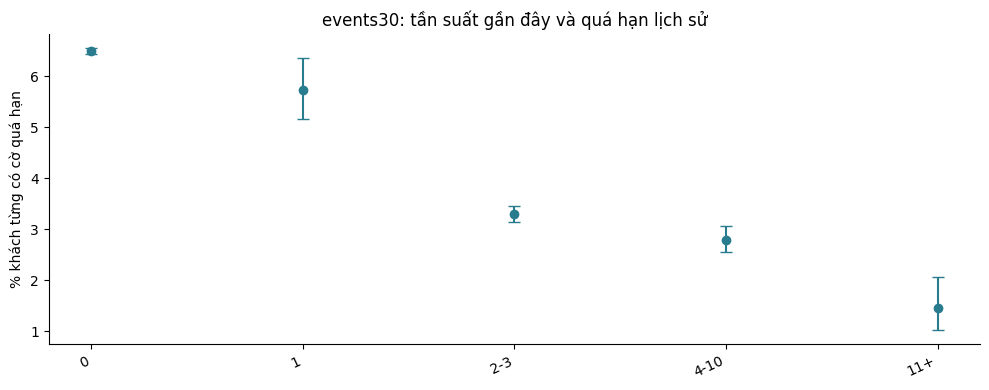

,group_name,n_clients,n_known,n_bad,pct_bad,low95,high95
0,0,876006,701729,46539.0,6.632,6.574,6.691
1,1,10129,5763,512.0,8.884,8.177,9.646
2,2-3,74863,72286,2476.0,3.425,3.295,3.560
3,4-10,32610,31441,1128.0,3.588,3.388,3.799
4,11+,6920,6804,161.0,2.366,2.031,2.755


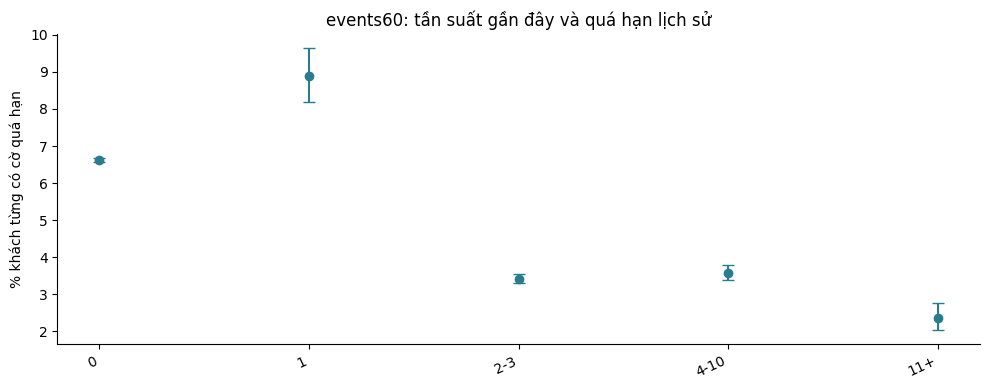

,group_name,n_clients,n_known,n_bad,pct_bad,low95,high95
0,0,842262,671173,44559.0,6.639,6.580,6.699
1,1,11732,5980,636.0,10.635,9.879,11.442
2,2-3,87531,83996,3221.0,3.835,3.707,3.967
3,4-10,45846,44003,1938.0,4.404,4.216,4.600
4,11+,13157,12871,462.0,3.589,3.282,3.925


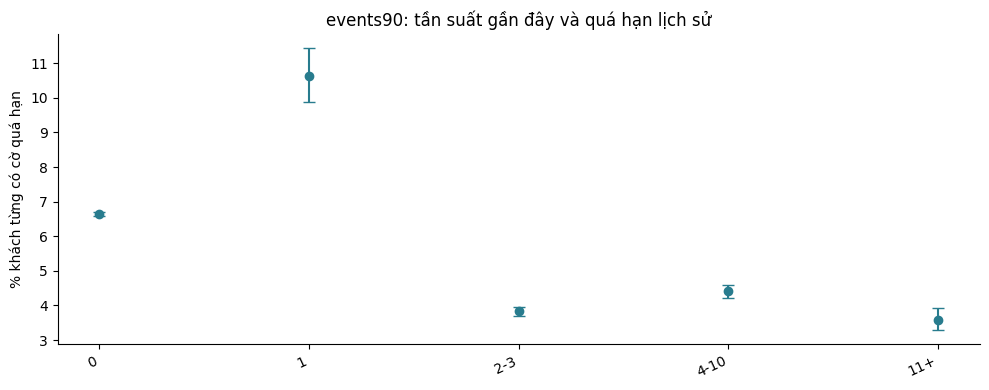

,group_name,n_clients,n_known,n_bad,pct_bad,low95,high95
0,0,952097,772574,49016.0,6.345,6.290,6.399
1,1,40113,37552,1476.0,3.931,3.739,4.132
2,2-3,7934,7548,311.0,4.120,3.695,4.593
3,4-10,369,341,13.0,3.812,2.241,6.412
4,11+,15,8,0.0,0.000,0.000,32.442


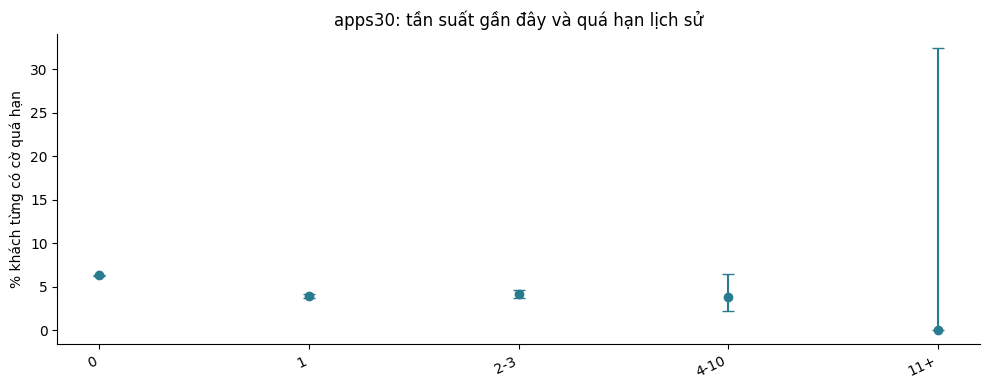

,group_name,n_clients,n_known,n_bad,pct_bad,low95,high95
0,0,904136,727754,46993.0,6.457,6.401,6.514
1,1,76365,71312,2947.0,4.133,3.989,4.281
2,2-3,18892,17914,822.0,4.589,4.292,4.905
3,4-10,1104,1025,54.0,5.268,4.060,6.811
4,11+,31,18,0.0,0.000,0.000,17.588


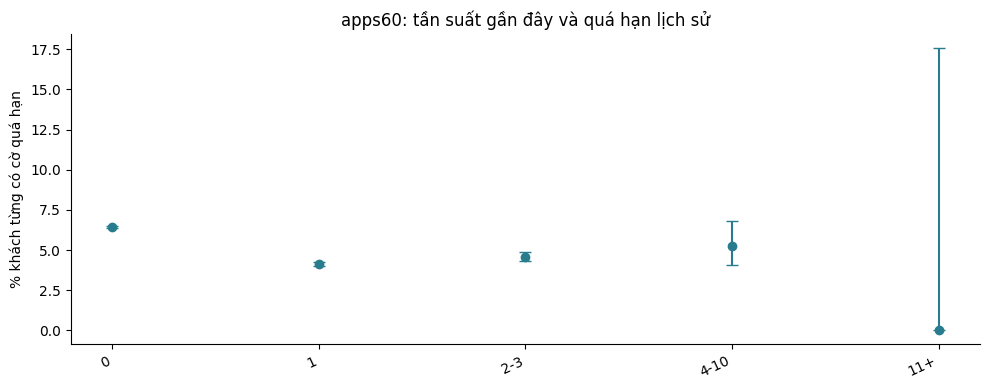

,group_name,n_clients,n_known,n_bad,pct_bad,low95,high95
0,0,869794,696175,45225.0,6.496,6.439,6.554
1,1,99196,92104,4091.0,4.442,4.311,4.577
2,2-3,29226,27624,1336.0,4.836,4.590,5.096
3,4-10,2245,2082,160.0,7.685,6.617,8.909
4,11+,67,38,4.0,10.526,4.170,24.131


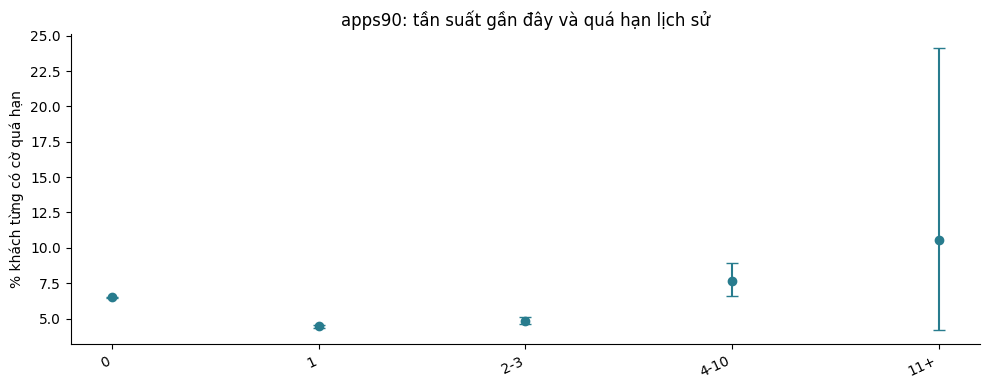

Chưa có thứ tự thời gian giữa tần suất và lần quá hạn; không coi đây là kiểm chứng dự báo.


In [12]:
con.execute(f"""CREATE TABLE activity AS
WITH b AS (SELECT SKP_CLIENT,
 count(*) FILTER (WHERE DTIME_EVENT>=TIMESTAMP '{END}'-INTERVAL 30 DAY) events30,
 count(*) FILTER (WHERE DTIME_EVENT>=TIMESTAMP '{END}'-INTERVAL 60 DAY) events60,
 count(*) events90, count(DISTINCT DTIME_EVENT::date) days90, count(DISTINCT ACTION) actions90
 FROM behavior WHERE DTIME_EVENT>=TIMESTAMP '{END}'-INTERVAL 90 DAY AND DTIME_EVENT<TIMESTAMP '{END}' GROUP BY 1),
 a AS (SELECT SKP_CLIENT,
 count(*) FILTER (WHERE APPLY_CONTRACT_TIME>=TIMESTAMP '{END}'-INTERVAL 30 DAY) apps30,
 count(*) FILTER (WHERE APPLY_CONTRACT_TIME>=TIMESTAMP '{END}'-INTERVAL 60 DAY) apps60,
 count(*) apps90, avg(gap_days) mean_gap90, count(*) FILTER (WHERE gap_days=0) zero_gaps
 FROM (SELECT SKP_CLIENT, APPLY_CONTRACT_TIME,
 date_diff('second', lag(APPLY_CONTRACT_TIME) OVER (PARTITION BY SKP_CLIENT
 ORDER BY APPLY_CONTRACT_TIME,SKP_CREDIT_CASE), APPLY_CONTRACT_TIME)/86400.0 gap_days
 FROM c WHERE APPLY_CONTRACT_TIME>=TIMESTAMP '{END}'-INTERVAL 90 DAY) GROUP BY 1)
SELECT u.SKP_CLIENT, coalesce(events30,0) events30, coalesce(events60,0) events60, coalesce(events90,0) events90,
 coalesce(days90,0) days90, coalesce(actions90,0) actions90,
 coalesce(apps30,0) apps30, coalesce(apps60,0) apps60, coalesce(apps90,0) apps90,
 mean_gap90, coalesce(zero_gaps,0) zero_gaps
FROM customer u LEFT JOIN b USING(SKP_CLIENT) LEFT JOIN a USING(SKP_CLIENT)
""")
activity_summary = []
for col in ['events30','events60','events90','days90','actions90','apps30','apps60','apps90','mean_gap90']:
    t = q(f"SELECT '{col}' feature, count({col}) n_known, count(*) FILTER (WHERE {col}=0) n_zero, quantile_cont({col},[.5,.9,.99]) quantiles, max({col}) maximum FROM activity")
    activity_summary.append(t)
display(pd.concat(activity_summary,ignore_index=True))
display(q('SELECT sum(zero_gaps) simultaneous_application_gaps FROM activity'))
activity_evidence = {}
for col in ['events30','events60','events90','apps30','apps60','apps90']:
    groups = q(f"""SELECT CASE WHEN {col}=0 THEN '0' WHEN {col}=1 THEN '1'
    WHEN {col}<=3 THEN '2-3' WHEN {col}<=10 THEN '4-10' ELSE '11+' END group_name,
    count(*) n_clients, count(ever_due) n_known, sum(ever_due) n_bad
    FROM client JOIN activity USING(SKP_CLIENT) GROUP BY 1
    ORDER BY min({col})""")
    activity_evidence[col] = rate_plot(groups, f'{col}: tần suất gần đây và quá hạn lịch sử')
print('Chưa có thứ tự thời gian giữa tần suất và lần quá hạn; không coi đây là kiểm chứng dự báo.')

### 6.2. Digital_Engagement
Phân biệt không dùng app, thiếu/không hợp lệ và các mức sử dụng dương. App chỉ phản ánh kênh số, không trực tiếp là kỷ luật trả nợ. Các nhóm dùng app có thể khác nhau về sản phẩm; kiểm tra thêm bên dưới. Cửa sổ tính AVG_SESSION_PER_WEEK_2025 chưa được xác nhận nên không dùng làm biến quá khứ cho một nhãn tương lai.

,group_name,n_clients,n_known,n_bad,n_dti,median_dti,pct_bad,low95,high95
0,1. No sessions,930051,747548,47467.0,338561,0.129,6.350,6.295,6.405
1,"2. (0,1]/week",51208,51207,2615.0,30206,0.123,5.107,4.919,5.301
2,"3. (1,3]/week",15520,15519,590.0,7808,0.160,3.802,3.512,4.114
3,4. >3/week,3749,3749,144.0,702,0.210,3.841,3.272,4.505


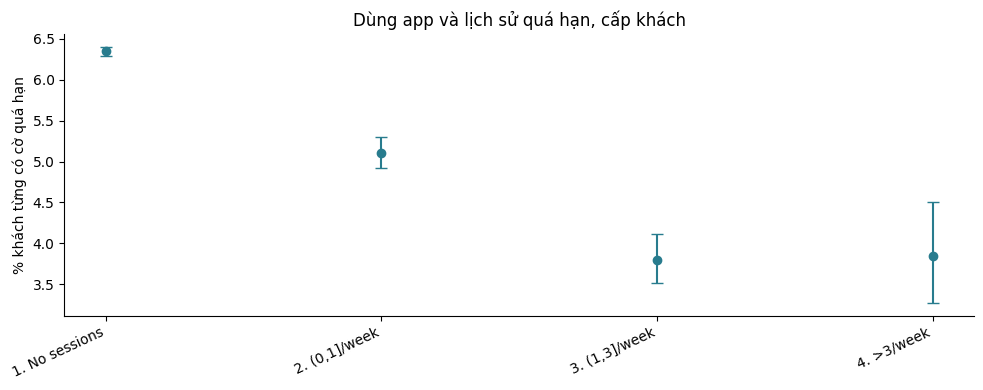

,positive_session_quantiles
0,"[0.41, 2.18, 5.95, 37.73]"


,PRODUCT,app_group,n_client_product,n_known,n_bad,pct_due
0,BNPL,No sessions,144245,144245,3231.0,2.239939
1,BNPL,Uses app,18234,18234,367.0,2.012723
2,CC,No sessions,71971,71971,1880.0,2.612163
3,CC,Uses app,8416,8416,171.0,2.031844
4,CD,No sessions,665617,665617,31063.0,4.666798
5,CD,Uses app,63659,63659,2185.0,3.432350
6,CL,No sessions,137580,137580,3338.0,2.426225
7,CL,Uses app,15580,15580,382.0,2.451861
8,CW,No sessions,19429,19429,552.0,2.841114
9,CW,Uses app,2071,2071,30.0,1.448576


Một khách có thể thuộc nhiều sản phẩm; không cộng các dòng sản phẩm để ra số khách duy nhất.


In [13]:
app_groups = q("""SELECT CASE WHEN app_sessions IS NULL OR app_sessions<0 THEN '0. Unknown'
 WHEN app_sessions=0 THEN '1. No sessions' WHEN app_sessions<=1 THEN '2. (0,1]/week'
 WHEN app_sessions<=3 THEN '3. (1,3]/week' ELSE '4. >3/week' END group_name,
 count(*) n_clients, count(ever_due) n_known, sum(ever_due) n_bad,
 count(dti) n_dti, median(dti) median_dti
 FROM client GROUP BY 1 ORDER BY 1""")
app_evidence = rate_plot(app_groups, 'Dùng app và lịch sử quá hạn, cấp khách')
display(q("""SELECT quantile_cont(app_sessions,[.5,.9,.99,1]) positive_session_quantiles
 FROM client WHERE app_sessions>0"""))
display(q("""WITH cp AS (SELECT SKP_CLIENT, PRODUCT, max(any_due) ever_due
 FROM c WHERE IS_SIGNED=1 AND signed_age>=120 GROUP BY 1,2)
 SELECT PRODUCT, CASE WHEN app_sessions>0 THEN 'Uses app'
 WHEN app_sessions=0 THEN 'No sessions' ELSE 'Unknown' END app_group,
 count(*) n_client_product, count(cp.ever_due) n_known, sum(cp.ever_due) n_bad, 100*avg(cp.ever_due) pct_due
 FROM cp JOIN client USING(SKP_CLIENT) GROUP BY 1,2 ORDER BY 1,2
"""))
print('Một khách có thể thuộc nhiều sản phẩm; không cộng các dòng sản phẩm để ra số khách duy nhất.')

## 7. Mối liên hệ giữa các yếu tố ở cấp khách
Spearman phù hợp để khảo sát quan hệ đơn điệu với biến lệch phải. Không mã hóa loại thu nhập thành số thứ bậc tùy ý; phần đó đã có bảng phân nhóm. Với Buffer chỉ dùng tỷ lệ bảo hiểm. Early index hiện chỉ là trung bình số cờ/4, không phải score đã chốt.

Mỗi cặp dùng các khách có đủ hai giá trị (pairwise); in ma trận cỡ mẫu tương ứng. Không điền 0 vào tỷ lệ không có lịch sử. Một số tương quan là **cơ học**: tỷ lệ Finished/Active/Written off cùng chia mẫu số, early_index và due_rate dùng cùng cờ. Không diễn giải heatmap thành causal drivers hay dùng nó làm validation score.

,n_known,pct_known,n_unique
dti,377277,37.71,53639
early_index,818023,81.76,104
completion_ratio,818023,81.76,87
writeoff_ratio,818023,81.76,30
rejection_ratio,1000528,100.00,562
down_payment_ratio,783376,78.30,295223
insurance_ratio,818023,81.76,182
events90,1000528,100.00,142
apps90,1000528,100.00,36
mean_gap90,31538,3.15,22023


,dti,early_index,completion_ratio,writeoff_ratio,rejection_ratio,down_payment_ratio,insurance_ratio,events90,apps90,mean_gap90,app_sessions,due_rate
dti,377277,377277,377277,377277,377277,369327,377277,377277,377277,10329,377277,377277
early_index,377277,818023,818023,818023,818023,783376,818023,818023,818023,29744,818023,818023
completion_ratio,377277,818023,818023,818023,818023,783376,818023,818023,818023,29744,818023,818023
writeoff_ratio,377277,818023,818023,818023,818023,783376,818023,818023,818023,29744,818023,818023
rejection_ratio,377277,818023,818023,818023,1000528,783376,818023,1000528,1000528,31538,1000528,818023
down_payment_ratio,369327,783376,783376,783376,783376,783376,783376,783376,783376,29157,783376,783376
insurance_ratio,377277,818023,818023,818023,818023,783376,818023,818023,818023,29744,818023,818023
events90,377277,818023,818023,818023,1000528,783376,818023,1000528,1000528,31538,1000528,818023
apps90,377277,818023,818023,818023,1000528,783376,818023,1000528,1000528,31538,1000528,818023
mean_gap90,10329,29744,29744,29744,31538,29157,29744,31538,31538,31538,31538,29744


,dti,early_index,completion_ratio,writeoff_ratio,rejection_ratio,down_payment_ratio,insurance_ratio,events90,apps90,mean_gap90,app_sessions,due_rate
dti,1.000,-0.022,0.032,-0.003,0.003,0.140,0.263,0.183,0.148,0.155,0.010,-0.022
early_index,-0.022,1.000,-0.026,0.278,0.130,-0.029,0.059,-0.040,-0.029,-0.005,-0.019,1.000
completion_ratio,0.032,-0.026,1.000,-0.099,0.188,-0.001,0.154,-0.027,-0.071,0.128,-0.081,-0.026
writeoff_ratio,-0.003,0.278,-0.099,1.000,0.199,-0.017,0.121,-0.055,-0.036,0.012,-0.038,0.276
rejection_ratio,0.003,0.130,0.188,0.199,1.000,-0.029,0.108,0.006,0.042,0.190,-0.123,0.129
down_payment_ratio,0.140,-0.029,-0.001,-0.017,-0.029,1.000,0.240,0.039,-0.084,0.015,0.003,-0.029
insurance_ratio,0.263,0.059,0.154,0.121,0.108,0.240,1.000,0.086,-0.025,0.050,-0.013,0.059
events90,0.183,-0.040,-0.027,-0.055,0.006,0.039,0.086,1.000,0.301,0.204,0.030,-0.040
apps90,0.148,-0.029,-0.071,-0.036,0.042,-0.084,-0.025,0.301,1.000,0.158,0.018,-0.029
mean_gap90,0.155,-0.005,0.128,0.012,0.190,0.015,0.050,0.204,0.158,1.000,-0.002,-0.005


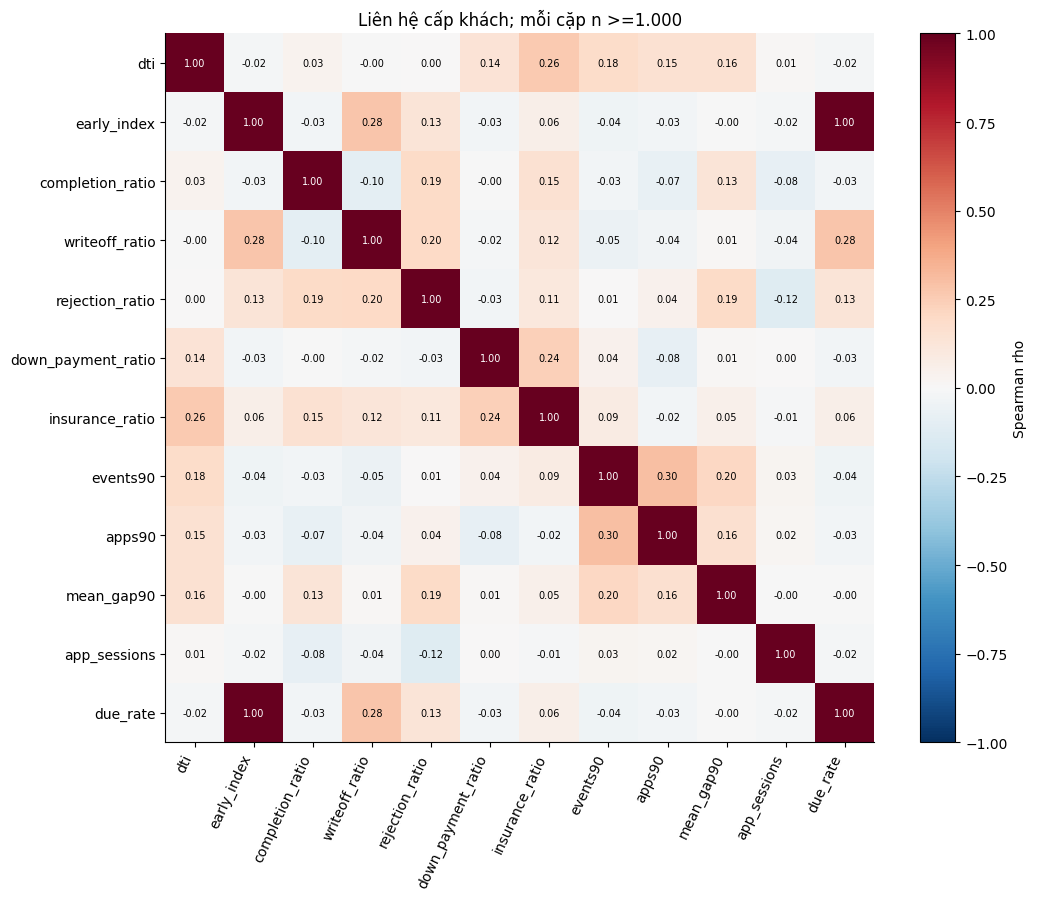

In [14]:
features = q("""SELECT dti, early_index, completion_ratio, writeoff_ratio, rejection_ratio,
 down_payment_ratio, insurance_ratio, events90, apps90, mean_gap90, app_sessions, due_rate
 FROM client JOIN activity USING(SKP_CLIENT)""")
coverage = pd.DataFrame({'n_known': features.notna().sum(), 'pct_known':100*features.notna().mean(),
                         'n_unique':features.nunique()})
display(coverage.round(2))
correlation = features.corr(method='spearman', min_periods=1000)
known = features.notna().astype('int64')
pair_n = known.T.dot(known)
display(pair_n)
display(correlation.round(3))
fig, ax = plt.subplots(figsize=(11,9))
im = ax.imshow(correlation, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation)),correlation.columns,rotation=65,ha='right')
ax.set_yticks(range(len(correlation)),correlation.index)
for i in range(len(correlation)):
    for j in range(len(correlation)):
        value = correlation.iloc[i,j]
        if pd.notna(value):
            ax.text(j,i,f'{value:.2f}',ha='center',va='center',fontsize=7,color='white' if abs(value)>.65 else 'black')
fig.colorbar(im, ax=ax, label='Spearman rho'); ax.set_title('Liên hệ cấp khách; mỗi cặp n >=1.000')
plt.tight_layout(); plt.show()
assert np.isfinite(features.to_numpy(dtype=float,na_value=np.nan)[features.notna().to_numpy()]).all()
del known

## 8. Tổng hợp bằng chứng cho bước 3 và kiểm tra cuối
Các bảng trên giúp quyết định giữ/bỏ/proxy, chưa tự động chứng minh chiều tác động trong pipeline. Bảng dưới ghi mức khả dụng của từng đặc trưng. Cần xem số khách đủ dữ liệu cùng với phân phối và nhóm sản phẩm, không chỉ hệ số tương quan.

Trước khi scoring cần chốt: cách cập nhật thu nhập, xử lý nghĩa vụ thiếu ở BNPL/CC, mức tin cậy cho khách chưa từng ký, ý nghĩa Paid off, cửa sổ quan sát cờ DUE, giới hạn proxy loại thu nhập/bảo hiểm/app. Không phạt khách chỉ vì thiếu dữ liệu. Tỷ lệ lịch sử ở đây không đủ để xác nhận các quy tắc phạt, chặn trần hoặc trọng số.

Bước 4 nên dùng thiết kế kiểm chứng độc lập nếu có mốc nhãn phù hợp; không dùng chính cờ đã cấu thành score để tuyên bố score dự báo tốt.

In [15]:
availability = q("""SELECT 'DTI' feature, count(dti) n_usable, 'Chỉ Active có đủ ANNUITY và thu nhập dương' limitation FROM client
 UNION ALL SELECT 'Income_Stability', count(*) FILTER (WHERE income_type IS NOT NULL AND income_type<>'XNA'), 'Proxy loại thu nhập; không đo ổn định lương' FROM client
 UNION ALL SELECT 'Early_Delinquency_Index', count(early_index), 'Cờ 0/1; chưa xác nhận kỳ đã đến hạn' FROM client
 UNION ALL SELECT 'Contract_Completion_Ratio', count(completion_ratio), 'Finished riêng; Paid off và Rejected cần diễn giải riêng' FROM client
 UNION ALL SELECT 'Down_Payment_Ratio', count(down_payment_ratio), 'Chỉ khách có CD/TW đã ký và số tiền hợp lệ' FROM client
 UNION ALL SELECT 'Buffer_And_Protection', count(insurance_ratio), 'Chỉ proxy bảo hiểm; không có tài sản' FROM client
 UNION ALL SELECT 'Credit_Hunger_Velocity', count(*), 'Số đếm quan sát; 0 không khẳng định không có nhu cầu' FROM activity
 UNION ALL SELECT 'Digital_Engagement', count(*) FILTER (WHERE app_sessions>=0), 'Chưa rõ cửa sổ tổng hợp năm 2025' FROM client
""")
availability['pct_clients'] = 100*availability.n_usable/q('SELECT count(*) FROM client').iloc[0,0]
display(availability.round(2))
checks = q("""SELECT
 (SELECT count(*)=count(DISTINCT SKP_CLIENT) FROM activity) unique_activity,
 (SELECT count(*) FROM activity)=(SELECT count(*) FROM client) same_population,
 (SELECT count(*) FROM activity WHERE NOT (events30<=events60 AND events60<=events90
    AND apps30<=apps60 AND apps60<=apps90))=0 nested_windows,
 (SELECT count(*) FROM client WHERE dti IS NOT NULL AND
    (income<=0 OR n_active=0 OR n_active_known<>n_active))=0 valid_dti_population,
 (SELECT count(*) FROM client WHERE n_signed=0 AND
    (early_index IS NOT NULL OR completion_ratio IS NOT NULL OR ever_due IS NOT NULL))=0 no_history_is_missing,
 (SELECT count(*) FROM c WHERE down_payment<0 OR down_payment>1)=0 valid_down_payment
""")
display(checks)
assert checks.iloc[0].all(), 'Cần kiểm tra lại định nghĩa hoặc phép nối.'
print('Hoàn tất thống kê 8 đặc trưng. Không tạo Financial Health Score hoặc sửa dữ liệu nguồn.')
con.close()

,feature,n_usable,limitation,pct_clients
0,DTI,377277,Chỉ Active có đủ ANNUITY và thu nhập dương,37.71
1,Income_Stability,721470,Proxy loại thu nhập; không đo ổn định lương,72.11
2,Early_Delinquency_Index,818023,Cờ 0/1; chưa xác nhận kỳ đã đến hạn,81.76
3,Contract_Completion_Ratio,818023,Finished riêng; Paid off và Rejected cần diễn ...,81.76
4,Down_Payment_Ratio,783376,Chỉ khách có CD/TW đã ký và số tiền hợp lệ,78.30
5,Buffer_And_Protection,818023,Chỉ proxy bảo hiểm; không có tài sản,81.76
6,Credit_Hunger_Velocity,1000528,Số đếm quan sát; 0 không khẳng định không có n...,100.00
7,Digital_Engagement,1000528,Chưa rõ cửa sổ tổng hợp năm 2025,100.00


,unique_activity,same_population,nested_windows,valid_dti_population,no_history_is_missing,valid_down_payment
0,True,True,True,True,True,True


Hoàn tất thống kê 8 đặc trưng. Không tạo Financial Health Score hoặc sửa dữ liệu nguồn.
